TITANIC DATASET
Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

MISSING VALUES COUNT
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin      

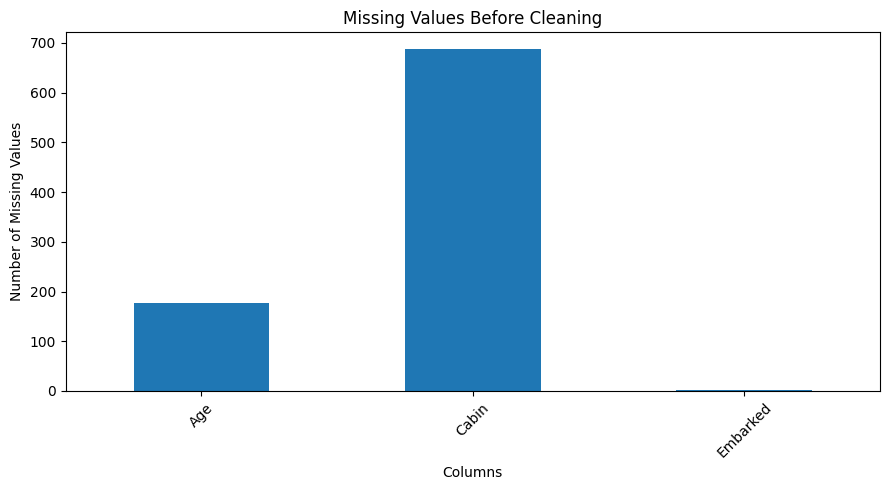


MISSING VALUES AFTER CLEANING
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

CLEANED DATASET


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S



Original Dataset Shape: (891, 12)
Cleaned Dataset Shape: (891, 11)


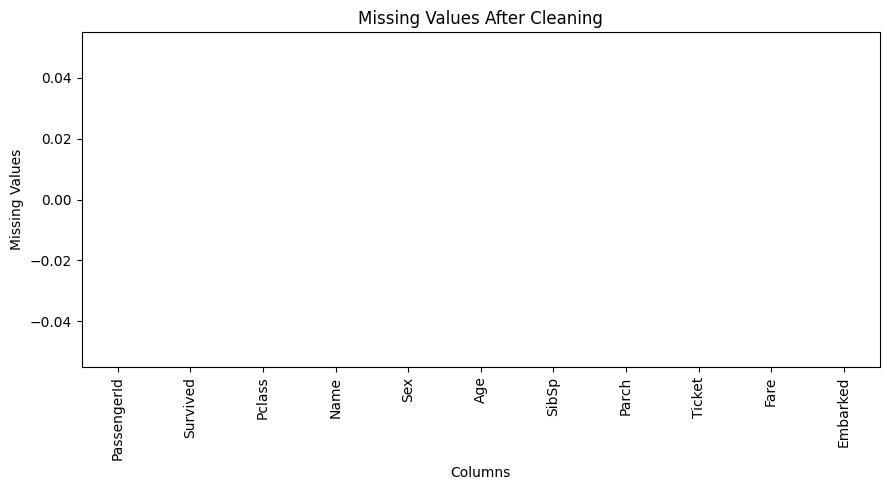


SUCCESS! Cleaned dataset saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2. Load Titanic dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print("TITANIC DATASET")
print("Shape:", df.shape)
display(df.head())

# 3. Dataset information
print("\nDATASET INFORMATION")
df.info()

# 4. Analyse missing values
print("\nMISSING VALUES COUNT")
print(df.isnull().sum())

print("\nMISSING VALUE PERCENTAGE")
print((df.isnull().mean() * 100).round(2))

# 5. Visualize missing values
missing = df.isnull().sum()
missing = missing[missing > 0]

plt.figure(figsize=(9, 5))
missing.plot(kind="bar")
plt.title("Missing Values Before Cleaning")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 6. Create a cleaned copy
cleaned_df = df.copy()

# 7. Handle numerical missing values using median
cleaned_df["Age"] = cleaned_df["Age"].fillna(
    cleaned_df["Age"].median()
)

# Handle Fare if missing values exist
cleaned_df["Fare"] = cleaned_df["Fare"].fillna(
    cleaned_df["Fare"].median()
)

# 8. Handle categorical missing values using mode
cleaned_df["Embarked"] = cleaned_df["Embarked"].fillna(
    cleaned_df["Embarked"].mode()[0]
)

# 9. Drop Cabin column because it has many missing values
cleaned_df = cleaned_df.drop(columns=["Cabin"])

# 10. Remove any remaining incomplete rows
cleaned_df = cleaned_df.dropna()

# 11. Check missing values after cleaning
print("\nMISSING VALUES AFTER CLEANING")
print(cleaned_df.isnull().sum())

print("\nCLEANED DATASET")
display(cleaned_df.head())

print("\nOriginal Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", cleaned_df.shape)

# 12. Visualize after cleaning
remaining = cleaned_df.isnull().sum()

plt.figure(figsize=(9, 5))
remaining.plot(kind="bar")
plt.title("Missing Values After Cleaning")
plt.xlabel("Columns")
plt.ylabel("Missing Values")
plt.tight_layout()
plt.show()

# 13. Save cleaned dataset
cleaned_df.to_csv("cleaned_titanic.csv", index=False)

print("\nSUCCESS! Cleaned dataset saved successfully.")

# 14. Download cleaned dataset
from google.colab import files
files.download("cleaned_titanic.csv")
